In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

file_path = "../data/raw/online_retail.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:

# 1. Count negative quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())

# 2. Count zero quantities
print("Zero quantities:", (df["Quantity"] == 0).sum())

# 3. Count negative prices
print("Negative unit prices:", (df["UnitPrice"] < 0).sum())

# 4. Count zero prices
print("Zero unit prices:", (df["UnitPrice"] == 0).sum())

# 5. Inspect cancellation invoices
print("\nCancellation invoice examples:")
print(
    df[df["InvoiceNo"].astype(str).str.startswith("C")].head(10)
)

# 6. Inspect negative-price records
print("\nNegative-price examples:")
print(df[df["UnitPrice"] < 0].head(10))


Negative quantities: 10624
Zero quantities: 0
Negative unit prices: 2
Zero unit prices: 2515

Cancellation invoice examples:
    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960           JAM MAKING SET WITH JARS        -6   

             InvoiceDate  UnitPrice  CustomerID         Country  
141  2010-12-01 

In [4]:

# 1. Check column data types and missing values
df.info()

# 2. Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Preview basic numerical statistics
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [5]:

# Show all records with negative unit prices
negative_price_rows = df[df["UnitPrice"] < 0]

print("Negative-price records:")
display(negative_price_rows)

# Inspect zero-price records
zero_price_rows = df[df["UnitPrice"] == 0]

print("Number of zero-price records:", len(zero_price_rows))
print("\nExamples of zero-price records:")
display(zero_price_rows.head(10))

# Calculate how many cancellation invoices exist
is_cancellation = df["InvoiceNo"].astype(str).str.startswith("C")

print("\nCancellation invoice rows:", is_cancellation.sum())


Negative-price records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Number of zero-price records: 2515

Examples of zero-price records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



Cancellation invoice rows: 9288


In [6]:

# Keep the original dataset unchanged
df_clean = df.copy()

# Remove only the two negative-price accounting adjustments
df_clean = df_clean[df_clean["UnitPrice"] >= 0].copy()

# Create a revenue column
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original rows:", len(df))
print("Rows after excluding negative prices:", len(df_clean))
print("Negative prices remaining:", (df_clean["UnitPrice"] < 0).sum())
print("Missing customer IDs:", df_clean["CustomerID"].isna().sum())
print("Total revenue (£):", round(df_clean["Revenue"].sum(), 2))


Original rows: 541909
Rows after excluding negative prices: 541907
Negative prices remaining: 0
Missing customer IDs: 135078
Total revenue (£): 9769872.05


In [7]:
# Check exact duplicate rows
print("Exact duplicate rows:", df_clean.duplicated().sum())

# Display some duplicate examples
duplicate_rows = df_clean[df_clean.duplicated(keep=False)]

display(duplicate_rows.head(10))

Exact duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95


In [8]:
# Remove exact duplicate rows from the cleaned dataset
df_clean = df_clean.drop_duplicates().copy()

# Check the results
print("Rows after removing duplicates:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())
print("Total revenue (£):", round(df_clean["Revenue"].sum(), 2))

Rows after removing duplicates: 536639
Duplicates remaining: 0
Total revenue (£): 9748131.07


In [9]:
# Check missing values after cleaning
print("Missing values in each column:")
print(df_clean.isnull().sum())


print("\nTotal missing values:")
print(df_clean.isnull().sum().sum())

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135035
Country             0
Revenue             0
dtype: int64

Total missing values:
136489


In [10]:
# Inspect rows with missing product descriptions
missing_descriptions = df_clean[
    df_clean["Description"].isna()
]

print("Rows with missing descriptions:", len(missing_descriptions))

display(
    missing_descriptions[
        ["InvoiceNo", "StockCode", "Quantity",
         "UnitPrice", "CustomerID", "Country"]
    ].head(10)
)

Rows with missing descriptions: 1454


,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID,Country
622,536414,22139,56,0.0,NaN,United Kingdom
1970,536545,21134,1,0.0,NaN,United Kingdom
1971,536546,22145,1,0.0,NaN,United Kingdom
1972,536547,37509,1,0.0,NaN,United Kingdom
1987,536549,85226A,1,0.0,NaN,United Kingdom
1988,536550,85044,1,0.0,NaN,United Kingdom
2024,536552,20950,1,0.0,NaN,United Kingdom
2025,536553,37461,3,0.0,NaN,United Kingdom
2026,536554,84670,23,0.0,NaN,United Kingdom
2406,536589,21777,-10,0.0,NaN,United Kingdom


In [11]:
# Analyze rows with missing product descriptions
missing_desc = df_clean[df_clean["Description"].isna()]

print("Number of rows:", len(missing_desc))
print("Rows with zero price:", (missing_desc["UnitPrice"] == 0).sum())
print("Rows with negative quantity:", (missing_desc["Quantity"] < 0).sum())
print("Rows with missing CustomerID:", missing_desc["CustomerID"].isna().sum())
print("Total revenue (£):", round(missing_desc["Revenue"].sum(), 2))

Number of rows: 1454
Rows with zero price: 1454
Rows with negative quantity: 862
Rows with missing CustomerID: 1454
Total revenue (£): 0.0


In [12]:
# Remove rows with missing product descriptions
df_clean = df_clean.dropna(subset=["Description"]).copy()

# Check the results
print("Rows remaining:", len(df_clean))
print("Missing descriptions:", df_clean["Description"].isna().sum())
print("Missing customer IDs:", df_clean["CustomerID"].isna().sum())
print("Total revenue (£):", round(df_clean["Revenue"].sum(), 2))

Rows remaining: 535185
Missing descriptions: 0
Missing customer IDs: 133581
Total revenue (£): 9748131.07


In [13]:
# Convert InvoiceDate to datetime format
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Check the result
print("Data type:", df_clean["InvoiceDate"].dtype)
print("Earliest date:", df_clean["InvoiceDate"].min())
print("Latest date:", df_clean["InvoiceDate"].max())

Data type: datetime64[us]
Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00


#Time Based Analysis

In [14]:
# Create time-based columns
df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["MonthName"] = df_clean["InvoiceDate"].dt.strftime("%B")
df_clean["Day"] = df_clean["InvoiceDate"].dt.day
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

# Check the new columns
display(
    df_clean[
        ["InvoiceDate", "Year", "Month", "MonthName",
         "Day", "DayOfWeek", "Hour", "Revenue"]
    ].head(10)
)

,InvoiceDate,Year,Month,MonthName,Day,DayOfWeek,Hour,Revenue
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,15.30
1,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20.34
2,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,22.00
3,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20.34
4,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20.34
5,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,15.30
6,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,25.50
7,2010-12-01 08:28:00,2010,12,December,1,Wednesday,8,11.10
8,2010-12-01 08:28:00,2010,12,December,1,Wednesday,8,11.10
9,2010-12-01 08:34:00,2010,12,December,1,Wednesday,8,54.08


In [15]:
# Group sales by year and month
monthly_sales = (
    df_clean.groupby(["Year", "Month", "MonthName"])
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Transactions=("InvoiceNo", "nunique"),
        Items_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values(["Year", "Month"])
)

# Display the monthly sales summary
monthly_sales["Total_Revenue"] = monthly_sales["Total_Revenue"].round(2)

display(monthly_sales)

,Year,Month,MonthName,Total_Revenue,Total_Transactions,Items_Sold
0,2010,12,December,746723.61,1900,342135
1,2011,1,January,558448.56,1362,301161
2,2011,2,February,497026.41,1328,276552
3,2011,3,March,682013.98,1818,350869
4,2011,4,April,492367.84,1518,292145
5,2011,5,May,722094.10,2024,381228
6,2011,6,June,689977.23,1921,342389
7,2011,7,July,680156.99,1772,393633
8,2011,8,August,703510.58,1653,408003
9,2011,9,September,1017596.68,2228,555818


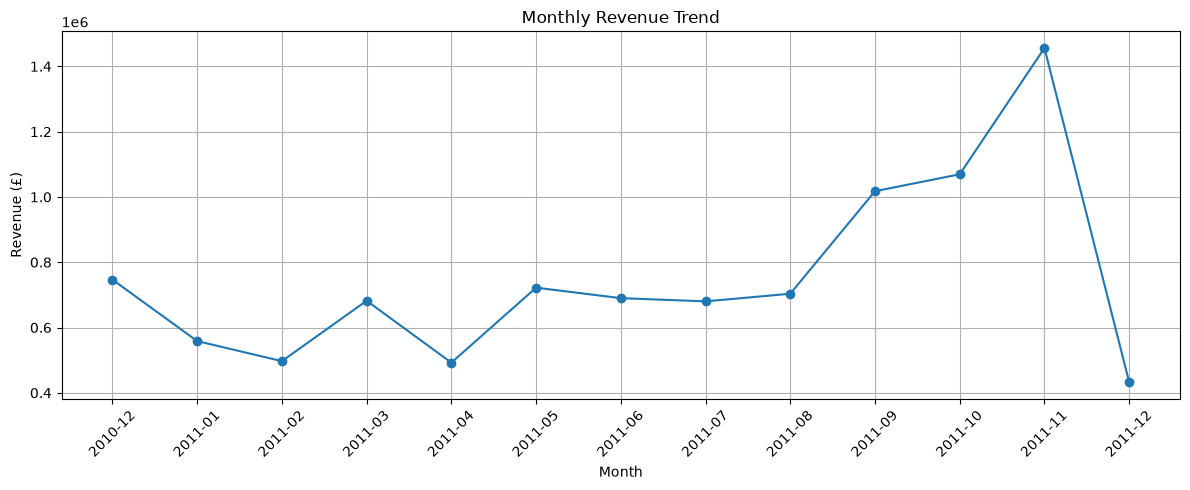

In [16]:
import matplotlib.pyplot as plt

# Create a readable month label
monthly_sales["Period"] = (
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Period"],
    monthly_sales["Total_Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
# Group revenue by day of the week
weekday_sales = (
    df_clean.groupby("DayOfWeek")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Transactions=("InvoiceNo", "nunique"),
        Items_Sold=("Quantity", "sum")
    )
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
    .reset_index()
)

weekday_sales["Total_Revenue"] = (
    weekday_sales["Total_Revenue"].round(2)
)

display(weekday_sales)

,DayOfWeek,Total_Revenue,Total_Transactions,Items_Sold
0,Monday,1584895.30,3960.0,813819.0
1,Tuesday,1965703.61,4430.0,965110.0
2,Wednesday,1730088.43,4496.0,976063.0
3,Thursday,2108701.53,5353.0,1165620.0
4,Friday,1560082.74,3824.0,793234.0
5,Saturday,NaN,NaN,NaN
6,Sunday,798659.46,2381.0,462263.0


In [18]:
# Count records for each day of the week
print(df_clean["DayOfWeek"].value_counts())

# Check the earliest and latest dates again
print("\nDate range:")
print(df_clean["InvoiceDate"].min())
print(df_clean["InvoiceDate"].max())

DayOfWeek
Thursday     102749
Tuesday      100772
Monday        94257
Wednesday     93396
Friday        81205
Sunday        62806
Name: count, dtype: int64

Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00


In [19]:
# Group sales by hour
hourly_sales = (
    df_clean.groupby("Hour")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Transactions=("InvoiceNo", "nunique"),
        Items_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Hour")
)

hourly_sales["Total_Revenue"] = (
    hourly_sales["Total_Revenue"].round(2)
)

display(hourly_sales)

,Hour,Total_Revenue,Total_Transactions,Items_Sold
0,6,-497.35,22,-86
1,7,31009.32,31,15361
2,8,281723.02,621,157728
3,9,766524.17,1749,429395
4,10,1327329.89,2826,682524
5,11,1146457.49,3009,639240
6,12,1357595.12,3797,816528
7,13,1172985.87,3246,677110
8,14,1113532.86,2924,570691
9,15,1186819.41,2820,609825


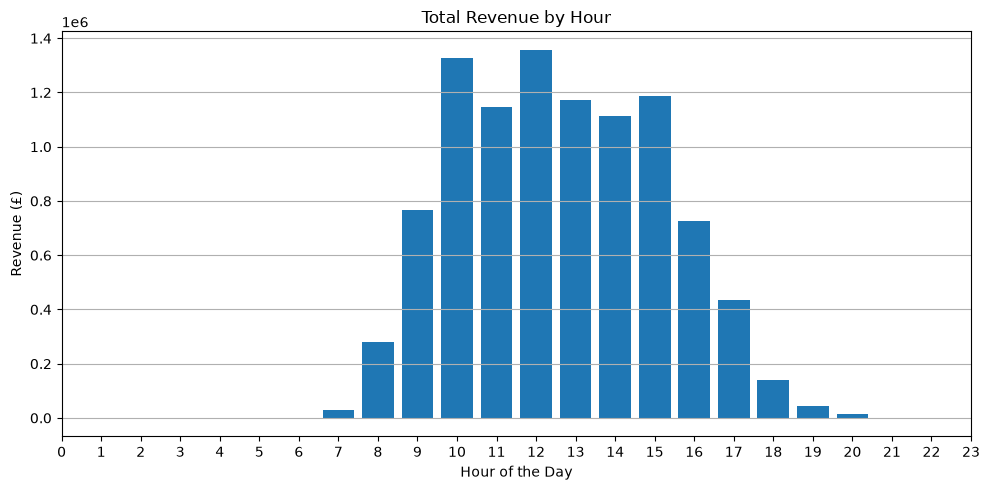

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    hourly_sales["Hour"],
    hourly_sales["Total_Revenue"]
)

plt.title("Total Revenue by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Revenue (£)")
plt.xticks(range(0, 24))
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [21]:

# Identify cancellation invoices
df_clean["IsCancellation"] = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

# Identify rows with returned or negative quantities
df_clean["IsNegativeQuantity"] = df_clean["Quantity"] < 0

print("Cancellation rows:", df_clean["IsCancellation"].sum())

print(
    "Cancellation invoices:",
    df_clean.loc[df_clean["IsCancellation"], "InvoiceNo"].nunique()
)

print("Negative-quantity rows:", df_clean["IsNegativeQuantity"].sum())

print(
    "Negative-quantity rows without a C invoice:",
    (
        df_clean["IsNegativeQuantity"]
        & ~df_clean["IsCancellation"]
    ).sum()
)


Cancellation rows: 9251
Cancellation invoices: 3836
Negative-quantity rows: 9725
Negative-quantity rows without a C invoice: 474


In [22]:

unusual_rows = df_clean[
    (df_clean["Quantity"] < 0)
    & (~df_clean["IsCancellation"])
]

display(
    unusual_rows[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "UnitPrice",
            "CustomerID",
            "Country",
            "Revenue"
        ]
    ].head(10)
)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
7313,537032,21275,?,-30,2010-12-03 16:50:00,0.0,NaN,United Kingdom,-0.0
13217,537425,84968F,check,-20,2010-12-06 15:35:00,0.0,NaN,United Kingdom,-0.0
13218,537426,84968E,check,-35,2010-12-06 15:36:00,0.0,NaN,United Kingdom,-0.0
13264,537432,35833G,damages,-43,2010-12-06 16:10:00,0.0,NaN,United Kingdom,-0.0
21338,538072,22423,faulty,-13,2010-12-09 14:10:00,0.0,NaN,United Kingdom,-0.0
21518,538090,20956,?,-723,2010-12-09 14:48:00,0.0,NaN,United Kingdom,-0.0
22296,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.0,NaN,United Kingdom,-0.0
22297,538162,46000M,Dotcom sales,-100,2010-12-09 17:25:00,0.0,NaN,United Kingdom,-0.0
42564,540010,22501,reverse 21/5/10 adjustment,-100,2011-01-04 11:13:00,0.0,NaN,United Kingdom,-0.0
42566,540012,22502,reverse 21/5/10 adjustment,-100,2011-01-04 11:14:00,0.0,NaN,United Kingdom,-0.0


In [23]:

# 1. Cancellation invoices
cancellations = df_clean[
    df_clean["IsCancellation"]
].copy()

# 2. Negative quantities on invoices not marked as cancellations
other_negative_rows = df_clean[
    (df_clean["Quantity"] < 0)
    & (~df_clean["IsCancellation"])
].copy()

# 3. Positive-quantity rows on invoices not marked as cancellations
normal_sales = df_clean[
    (~df_clean["IsCancellation"])
    & (df_clean["Quantity"] > 0)
].copy()

print("Cancellation rows:", len(cancellations))
print("Other negative-quantity rows:", len(other_negative_rows))
print("Positive-quantity sales rows:", len(normal_sales))

print("\nRevenue comparison:")
print("All records:", round(df_clean["Revenue"].sum(), 2))
print("Cancellation invoices:", round(cancellations["Revenue"].sum(), 2))
print("Other negative-quantity rows:", round(other_negative_rows["Revenue"].sum(), 2))
print("Positive-quantity sales:", round(normal_sales["Revenue"].sum(), 2))


Cancellation rows: 9251
Other negative-quantity rows: 474
Positive-quantity sales rows: 525460

Revenue comparison:
All records: 9748131.07
Cancellation invoices: -893979.73
Other negative-quantity rows: 0.0
Positive-quantity sales: 10642110.8


In [24]:

gross_sales = df_clean.loc[
    (~df_clean["IsCancellation"])
    & (df_clean["Quantity"] > 0),
    "Revenue"
].sum()

cancellation_value = -df_clean.loc[
    df_clean["IsCancellation"],
    "Revenue"
].sum()

net_revenue = df_clean["Revenue"].sum()

revenue_summary = pd.DataFrame({
    "Measure": [
        "Gross Sales",
        "Cancellation Value",
        "Net Revenue"
    ],
    "Amount_GBP": [
        gross_sales,
        cancellation_value,
        net_revenue
    ]
})

revenue_summary["Amount_GBP"] = (
    revenue_summary["Amount_GBP"].round(2)
)

display(revenue_summary)


,Measure,Amount_GBP
0,Gross Sales,10642110.80
1,Cancellation Value,893979.73
2,Net Revenue,9748131.07


In [25]:
# Save cleaned dataset as CSV
df_clean.to_csv(
    "online_retail_cleaned.csv",
    index=False
)


print("Cleaned CSV saved successfully!")

Cleaned CSV saved successfully!
